<a href="https://colab.research.google.com/github/cracker38/AgriLoss-Value-Intelligence-Rwanda/blob/main/NISR_2026_Agri_Productivity_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Project Objective
2. Data Sources
3. Import Libraries
4. Load Dataset
5. Data Understanding
6. Data Cleaning
7. Exploratory Data Analysis
8. Feature Engineering
9. Machine Learning
10. Model Evaluation
11. Conclusions


## 2. Data Sources

The primary data source for this project is the **Rwanda Seasonal Agricultural Survey (SAS) 2024**, provided by the **National Institute of Statistics of Rwanda (NISR)**.

The dataset covers three agricultural seasons:

- **Season A**
- **Season B**
- **Season C**

For each agricultural season, four categories of datasets are available:

1. **Production**
2. **Agricultural Practice**
3. **Fertilizer and Pesticide**
4. **Screening**

Therefore, the project uses **12 JSON datasets** covering agricultural production, farming practices, agricultural inputs, and screening information across Rwanda.

The datasets will be analyzed to identify patterns and relationships that can support agricultural productivity analysis and data-driven decision-making.

In [1]:
import os
import requests

# Google Drive is already mounted
dataset_path = "/content/drive/MyDrive/NISR_Hackathon/datasets"

# Create the folder if needed
os.makedirs(dataset_path, exist_ok=True)

# Your 12 Google Drive files
files = {
    "sas_2024_seasonA_agricultural_practice.json":
        "1uxhFqOhl9rGBDvWeH3f_odDn3ky7hdqs",

    "sas_2024_seasonA_fertilizer_pesticide.json":
        "1i-eF5L3aJ7iO_J4574_XMNr611DWGl-V",

    "sas_2024_seasonA_production.json":
        "11mujUOSPjCsVCA9HFSpiGT0qDq3b6tJ_",

    "sas_2024_seasonA_screening.json":
        "1mZW1V-e398svmN0eczGYdNNGud-cmDI-",

    "sas_2024_seasonB_agricultural_practice.json":
        "16lzKLqSTI1LDKtEmSIgYRgqB4tvtIkqf",

    "sas_2024_seasonB_fertilizer_pesticide.json":
        "1z_v6tnv0jHUXj1A4EilaOI-2HL1iT7z0",

    "sas_2024_seasonB_production.json":
        "1DNqf3JBgC_A3atCod9ZF0xe_kg5L_Mi8",

    "sas_2024_seasonB_screening.json":
        "1c3gcsqc4XiJ5clImRppLOKHEWtXAvgpX",

    "sas_2024_seasonC_agricultural_practice.json":
        "1DNgFsT3Tc-p6e1-o1bopefN1bpTCK6jX",

    "sas_2024_seasonC_fertilizer_pesticide.json":
        "1I-BSuQko4dPG0HTI_FOSmH4LIdXWbCfK",

    "sas_2024_seasonC_production.json":
        "14gLbOkGS4KMM3NytVRg5tuYMPeCWlY4j",

    "sas_2024_seasonC_screening.json":
        "1JvWCi3wkfp5HvnvUVEIETzICgrZVh_eC"
}

# Download files
for filename, file_id in files.items():

    destination = os.path.join(dataset_path, filename)

    print(f"Downloading: {filename}")

    url = f"https://drive.google.com/uc?export=download&id={file_id}"

    response = requests.get(url)

    if response.status_code == 200:
        with open(destination, "wb") as f:
            f.write(response.content)

        print("   ✅ Saved")
    else:
        print(f"   ❌ Failed: HTTP {response.status_code}")

# Verify
print("\n===================================")
print("CHECKING DATASETS")
print("===================================")

json_files = [
    file for file in os.listdir(dataset_path)
    if file.lower().endswith(".json")
]

print(f"\nTotal JSON datasets: {len(json_files)}")

for i, file in enumerate(sorted(json_files), 1):
    print(f"{i}. {file}")

Downloading: sas_2024_seasonA_agricultural_practice.json
   ✅ Saved
Downloading: sas_2024_seasonA_fertilizer_pesticide.json
   ✅ Saved
Downloading: sas_2024_seasonA_production.json
   ✅ Saved
Downloading: sas_2024_seasonA_screening.json
   ✅ Saved
Downloading: sas_2024_seasonB_agricultural_practice.json
   ✅ Saved
Downloading: sas_2024_seasonB_fertilizer_pesticide.json
   ✅ Saved
Downloading: sas_2024_seasonB_production.json
   ✅ Saved
Downloading: sas_2024_seasonB_screening.json
   ✅ Saved
Downloading: sas_2024_seasonC_agricultural_practice.json
   ✅ Saved
Downloading: sas_2024_seasonC_fertilizer_pesticide.json
   ✅ Saved
Downloading: sas_2024_seasonC_production.json
   ✅ Saved
Downloading: sas_2024_seasonC_screening.json
   ✅ Saved

CHECKING DATASETS

Total JSON datasets: 12
1. sas_2024_seasonA_agricultural_practice.json
2. sas_2024_seasonA_fertilizer_pesticide.json
3. sas_2024_seasonA_production.json
4. sas_2024_seasonA_screening.json
5. sas_2024_seasonB_agricultural_practice.json
6

In [ ]:
# ============================================
# 3. IMPORT LIBRARIES
# ============================================

import os
import json
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from IPython.display import display

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# ============================================
# 4. CHECK UPLOADED DATASETS
# ============================================

import os

# Path to the datasets stored in Google Drive
dataset_path = "/content/drive/MyDrive/NISR_Hackathon/datasets"

# Get all JSON files
json_files = [
    file for file in os.listdir(dataset_path)
    if file.lower().endswith(".json")
]

# Display number of datasets
print(f"Number of JSON files found: {len(json_files)}")
print()

# Display dataset names
for i, file in enumerate(sorted(json_files), start=1):
    print(f"{i}. {file}")

Number of JSON files found: 12

1. sas_2024_seasonA_agricultural_practice.json
2. sas_2024_seasonA_fertilizer_pesticide.json
3. sas_2024_seasonA_production.json
4. sas_2024_seasonA_screening.json
5. sas_2024_seasonB_agricultural_practice.json
6. sas_2024_seasonB_fertilizer_pesticide.json
7. sas_2024_seasonB_production.json
8. sas_2024_seasonB_screening.json
9. sas_2024_seasonC_agricultural_practice.json
10. sas_2024_seasonC_fertilizer_pesticide.json
11. sas_2024_seasonC_production.json
12. sas_2024_seasonC_screening.json


In [4]:

# ============================================================
# NISR 2026 BIG DATA HACKATHON
# DATASET SETUP AND VALIDATION
# Download only missing or invalid datasets
# ============================================================

import os
import json
import google.auth

from google.colab import drive, auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
from IPython.display import display

# ============================================================
# 1. GOOGLE DRIVE MOUNT — HANDLE EXISTING MOUNT POINTS
# ============================================================

def mount_google_drive():
    """Reuse an existing Drive mount or select an available mount point."""

    mount_points = [
        "/content/drive",
        "/content/gdrive"
    ]

    # Reuse Drive if it is already mounted at either location
    for point in mount_points:
        if os.path.ismount(point):
            if os.path.isdir(os.path.join(point, "MyDrive")):
                print(f"Google Drive already mounted: {point}")
                return point

    # Otherwise, select a mount point that is not occupied
    for point in mount_points:
        if not os.path.lexists(point):
            os.makedirs(point, exist_ok=True)
            drive.mount(point, force_remount=False)

            if os.path.isdir(os.path.join(point, "MyDrive")):
                print(f"Google Drive mounted successfully: {point}")
                return point

        elif os.path.isdir(point) and not os.listdir(point):
            drive.mount(point, force_remount=False)

            if os.path.isdir(os.path.join(point, "MyDrive")):
                print(f"Google Drive mounted successfully: {point}")
                return point

    raise RuntimeError(
        "Could not identify an available Google Drive mount point. "
        "Check the current Colab runtime before attempting a remount."
    )


MOUNT_POINT = mount_google_drive()

# ============================================================
# 2. CONFIGURE THE PERSISTENT DATASET DIRECTORY
# ============================================================

DATASET_PATH = os.path.join(
    MOUNT_POINT,
    "MyDrive",
    "M Training Deliverables",
    "NISR_Hackathon",
    "datasets"
)

os.makedirs(DATASET_PATH, exist_ok=True)

print("\n" + "=" * 75)
print("NISR DATASET CONFIGURATION")
print("=" * 75)
print("Storage:", DATASET_PATH)

# ============================================================
# 3. DATASET MANIFEST — 12 SAS 2024 JSON FILES
# ============================================================

FILES = {
    "sas_2024_seasonA_agricultural_practice.json":
        "1uxhFqOhl9rGBDvWeH3f_odDn3ky7hdqs",

    "sas_2024_seasonA_fertilizer_pesticide.json":
        "1i-eF5L3aJ7iO_J4574_XMNr611DWGl-V",

    "sas_2024_seasonA_production.json":
        "11mujUOSPjCsVCA9HFSpiGT0qDq3b6tJ_",

    "sas_2024_seasonA_screening.json":
        "1mZW1V-e398svmN0eczGYdNNGud-cmDI-",

    "sas_2024_seasonB_agricultural_practice.json":
        "16lzKLqSTI1LDKtEmSIgYRgqB4tvtIkqf",

    "sas_2024_seasonB_fertilizer_pesticide.json":
        "1z_v6tnv0jHUXj1A4EilaOI-2HL1iT7z0",

    "sas_2024_seasonB_production.json":
        "1DNqf3JBgC_A3atCod9ZF0xe_kg5L_Mi8",

    "sas_2024_seasonB_screening.json":
        "1c3gcsqc4XiJ5clImRppLOKHEWtXAvgpX",

    "sas_2024_seasonC_agricultural_practice.json":
        "1DNgFsT3Tc-p6e1-o1bopefN1bpTCK6jX",

    "sas_2024_seasonC_fertilizer_pesticide.json":
        "1I-BSuQko4dPG0HTI_FOSmH4LIdXWbCfK",

    "sas_2024_seasonC_production.json":
        "14gLbOkGS4KMM3NytVRg5tuYMPeCWlY4j",

    "sas_2024_seasonC_screening.json":
        "1JvWCi3wkfp5HvnvUVEIETzICgrZVh_eC",
}

# ============================================================
# 4. VALIDATE EXISTING JSON FILES
# ============================================================

def is_valid_json(path):
    """Return True only when the file exists and parses as JSON."""

    try:
        if not os.path.isfile(path):
            return False

        if os.path.getsize(path) == 0:
            return False

        with open(path, "r", encoding="utf-8-sig") as file:
            json.load(file)

        return True

    except (ValueError, OSError, UnicodeError):
        return False


# ============================================================
# 5. CHECK WHICH FILES NEED DOWNLOADING
# ============================================================

files_to_download = {
    filename: file_id
    for filename, file_id in FILES.items()
    if not is_valid_json(os.path.join(DATASET_PATH, filename))
}

valid_existing = len(FILES) - len(files_to_download)

print(f"\nExpected datasets: {len(FILES)}")
print(f"Already valid:     {valid_existing}")
print(f"Need downloading:  {len(files_to_download)}")

# ============================================================
# 6. DOWNLOAD ONLY MISSING OR INVALID FILES
# ============================================================

if not files_to_download:

    print("\nSUCCESS: All 12 datasets are already valid.")
    print("No downloads required.")

else:
    print("\nThe following datasets need attention:")
    for filename in files_to_download:
        print(" -", filename)

    auth.authenticate_user()

    credentials, _ = google.auth.default()
    drive_service = build(
        "drive",
        "v3",
        credentials=credentials,
        cache_discovery=False
    )

    for filename, file_id in files_to_download.items():

        destination = os.path.join(DATASET_PATH, filename)
        temporary_path = destination + ".download"

        try:
            print(f"\nProcessing: {filename}")

            request = drive_service.files().get_media(
                fileId=file_id
            )

            with open(temporary_path, "wb") as output_file:

                downloader = MediaIoBaseDownload(
                    output_file,
                    request,
                    chunksize=1024 * 1024
                )

                done = False

                while not done:
                    status, done = downloader.next_chunk()

                    if status:
                        print(
                            f"  Download progress: "
                            f"{status.progress() * 100:.1f}%"
                        )

            # Validate the downloaded file before replacing anything
            if not is_valid_json(temporary_path):
                raise ValueError(
                    "Downloaded content is not valid JSON. "
                    "Check the Drive file ID and access permissions."
                )

            # Replace the destination only after validation succeeds
            os.replace(temporary_path, destination)

            print(f"SUCCESS: {filename}")

        except Exception as error:

            if os.path.exists(temporary_path):
                os.remove(temporary_path)

            print(f"FAILED: {filename}")
            print(f"Reason: {error}")

# ============================================================
# 7. FINAL DATASET VERIFICATION
# ============================================================

verification = []

for filename in FILES:
    file_path = os.path.join(DATASET_PATH, filename)
    valid = is_valid_json(file_path)

    verification.append({
        "Dataset": filename,
        "Status": "VALID" if valid else "MISSING / INVALID",
        "Size (MB)": (
            round(os.path.getsize(file_path) / (1024 ** 2), 2)
            if valid else None
        )
    })

verification_df = pd.DataFrame(verification) if False else None

# Create the verification table without requiring pandas
print("\n" + "=" * 75)
print("FINAL VERIFICATION")
print("=" * 75)

for item in verification:
    print(f"{item['Status']:<20} {item['Dataset']}")

valid_count = sum(
    item["Status"] == "VALID"
    for item in verification
)

print(f"\nVerified datasets: {valid_count}/{len(FILES)}")
print(f"Persistent storage: {DATASET_PATH}")

if valid_count == len(FILES):
    print("\nREADY: Proceed to Data Understanding.")
else:
    print(
        "\nWARNING: Some datasets are still missing or invalid. "
        "Review the errors above before continuing."
    )


Mounted at /content/gdrive
Google Drive mounted successfully: /content/gdrive

NISR DATASET CONFIGURATION
Storage: /content/gdrive/MyDrive/M Training Deliverables/NISR_Hackathon/datasets

Expected datasets: 12
Already valid:     12
Need downloading:  0

SUCCESS: All 12 datasets are already valid.
No downloads required.

FINAL VERIFICATION
VALID                sas_2024_seasonA_agricultural_practice.json
VALID                sas_2024_seasonA_fertilizer_pesticide.json
VALID                sas_2024_seasonA_production.json
VALID                sas_2024_seasonA_screening.json
VALID                sas_2024_seasonB_agricultural_practice.json
VALID                sas_2024_seasonB_fertilizer_pesticide.json
VALID                sas_2024_seasonB_production.json
VALID                sas_2024_seasonB_screening.json
VALID                sas_2024_seasonC_agricultural_practice.json
VALID                sas_2024_seasonC_fertilizer_pesticide.json
VALID                sas_2024_seasonC_production.json
VALI

In [5]:

# ============================================================
# 5. DATA UNDERSTANDING — NISR 2026 BIG DATA HACKATHON
# Read existing datasets only; NO DOWNLOADS
# ============================================================

import os
import json
import pandas as pd
from IPython.display import display

DATASET_PATH = (
    "/content/gdrive/MyDrive/M Training Deliverables/"
    "NISR_Hackathon/datasets"
)

FILES = [
    f"sas_2024_season{s}_{category}.json"
    for s in ["A", "B", "C"]
    for category in [
        "agricultural_practice",
        "fertilizer_pesticide",
        "production",
        "screening"
    ]
]

datasets = {}
summary = []
errors = []

# ------------------------------------------------------------
# 1. LOAD EXISTING DATASETS
# ------------------------------------------------------------

for filename in FILES:
    path = os.path.join(DATASET_PATH, filename)

    print("\n" + "=" * 85)
    print(f"DATASET: {filename}")
    print("=" * 85)

    try:
        if not os.path.isfile(path):
            raise FileNotFoundError(
                "File is missing. Run the setup cell if necessary."
            )

        with open(path, "r", encoding="utf-8-sig") as file:
            raw_data = json.load(file)

        if isinstance(raw_data, list):
            df = pd.json_normalize(raw_data)

        elif isinstance(raw_data, dict):
            record_key = next(
                (
                    key for key in ("data", "results", "records", "items")
                    if isinstance(raw_data.get(key), list)
                ),
                None
            )

            df = (
                pd.json_normalize(raw_data[record_key])
                if record_key
                else pd.json_normalize(raw_data)
            )

        else:
            raise ValueError("Unsupported JSON structure.")

        name = filename.removesuffix(".json")
        datasets[name] = df

        rows, columns = df.shape
        missing = int(df.isna().sum().sum())
        duplicates = int(df.duplicated().sum())
        memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)

        print(f"Rows: {rows:,} | Columns: {columns:,}")
        print(f"Missing cells: {missing:,}")
        print(f"Duplicate rows: {duplicates:,}")
        print(f"Memory usage: {memory_mb:.2f} MB")

        # Column information
        print("\nCOLUMN INFORMATION")
        column_info = pd.DataFrame({
            "Column": df.columns.astype(str),
            "Data Type": df.dtypes.astype(str).values,
            "Missing Values": df.isna().sum().values,
            "Missing (%)": (
                (df.isna().mean() * 100).round(2).values
            )
        })
        display(column_info)

        # Preview
        print("\nFIRST FIVE RECORDS")
        display(df.head())

        # Numerical statistics
        print("\nNUMERICAL SUMMARY")
        numeric = df.select_dtypes(include="number")

        if not numeric.empty:
            display(numeric.describe().T)
        else:
            print("No numerical columns detected.")

        # Summary record
        summary.append({
            "Dataset": filename,
            "Rows": rows,
            "Columns": columns,
            "Missing Cells": missing,
            "Duplicate Rows": duplicates,
            "Memory (MB)": round(memory_mb, 2)
        })

    except Exception as error:
        errors.append({
            "Dataset": filename,
            "Error": str(error)
        })
        print(f"ERROR: {error}")

# ------------------------------------------------------------
# 2. OVERALL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("OVERALL DATA UNDERSTANDING SUMMARY")
print("=" * 85)

summary_df = pd.DataFrame(summary)

if not summary_df.empty:
    display(summary_df)

    print(f"Datasets loaded: {len(datasets)}/{len(FILES)}")
    print(f"Total rows: {summary_df['Rows'].sum():,}")
    print(f"Total columns: {summary_df['Columns'].sum():,}")
    print(f"Total missing cells: {summary_df['Missing Cells'].sum():,}")
    print(f"Total duplicate rows: {summary_df['Duplicate Rows'].sum():,}")
    print(
        f"Combined DataFrame memory: "
        f"{summary_df['Memory (MB)'].sum():.2f} MB"
    )

if errors:
    print("\nDATASETS REQUIRING ATTENTION")
    display(pd.DataFrame(errors))
else:
    print("\nAll 12 datasets were loaded successfully.")

print("\nData Understanding completed. No downloads were performed.")



DATASET: sas_2024_seasonA_agricultural_practice.json
Rows: 17,506 | Columns: 59
Missing cells: 0
Duplicate rows: 0
Memory usage: 51.17 MB

COLUMN INFORMATION


,Column,Data Type,Missing Values,Missing (%)
0,id,object,0,0.0
1,Segment_ID,object,0,0.0
2,s1q1,object,0,0.0
3,s1q2,object,0,0.0
4,s1q3,object,0,0.0
5,s1q4,object,0,0.0
6,s1q6,object,0,0.0
7,s1q7,object,0,0.0
8,s1q8,object,0,0.0
9,s1q9,object,0,0.0



FIRST FIVE RECORDS


,id,Segment_ID,s1q1,s1q2,s1q3,s1q4,s1q6,s1q7,s1q8,s1q9,...,s4q15,s4q16,s4q17_1,s4q17_2,s4q17_3,s4q18_1,s4q18_2,s4q18_3,s4q19,plot_weight
0,1,111003,Kigali,Nyarugenge,Agricultural land on hillside,3,20,Small scale farmer as individual,Male,55,...,,,,,,,,,,132.1108
1,2,111004,Kigali,Nyarugenge,Agricultural land on hillside,4,7,Small scale farmer as individual,Male,34,...,,,,,,,,,,326.3918
2,3,111007,Kigali,Nyarugenge,Agricultural land on hillside,7,23,Small scale farmer as individual,Female,64,...,,,,,,,,,,61.6604
3,4,114019,Kigali,Nyarugenge,Mixed,19,23,Small scale farmer as individual,Male,40,...,,,,,,,,,,1023.222
4,5,114019,Kigali,Nyarugenge,Mixed,19,1,Small scale farmer as individual,Male,64,...,,,,,,,,,,73.48241



NUMERICAL SUMMARY
No numerical columns detected.

DATASET: sas_2024_seasonA_fertilizer_pesticide.json
Rows: 22,105 | Columns: 64
Missing cells: 0
Duplicate rows: 0
Memory usage: 70.24 MB

COLUMN INFORMATION


...


FIRST FIVE RECORDS


,id,Segment_ID,s1q1,s1q2,s1q3,s1q4,s1q5_2,s1q13,s2q1,s2q3,...,s3q2_2,s3q3_1,s3q3_2,s3q5,s3q6,s3q7,plot_weight,CropCategory,Plot_size_ha,Crop_Area
0,1,111009,Kigali,Nyarugenge,Agricultural land on hillside,9,1,9,1,1,...,61%-70%,60,51%-60%,Yes,Yes,Between 16 -30/09,36.229675,Bush bean,0.0956858,0.0669801
1,2,111009,Kigali,Nyarugenge,Agricultural land on hillside,9,1,9,1,1,...,31%-40%,40,31%-40%,Yes,Yes,After 30/09,36.229675,Soybean,0.0956858,0.03349
2,3,111009,Kigali,Nyarugenge,Agricultural land on hillside,9,1,9,1,1,...,10% -20%,15,10% 20%,No,No,Other season,36.229675,Maize,0.0956858,0.0143529
3,4,111009,Kigali,Nyarugenge,Agricultural land on hillside,9,2,9,2,1,...,61%-70%,45,41%-50%,Yes,Yes,Between 16 -30/09,22.069442,Bush bean,0.1570799,0.102102
4,5,111009,Kigali,Nyarugenge,Agricultural land on hillside,9,2,9,2,1,...,10% -20%,10,10% 20%,No,No,Other season,22.069442,Maize,0.1570799,0.015708



NUMERICAL SUMMARY
No numerical columns detected.

OVERALL DATA UNDERSTANDING SUMMARY


,Dataset,Rows,Columns,Missing Cells,Duplicate Rows,Memory (MB)
0,sas_2024_seasonA_agricultural_practice.json,17506,59,0,0,51.17
1,sas_2024_seasonA_fertilizer_pesticide.json,22105,64,0,0,70.24
2,sas_2024_seasonA_production.json,39330,96,0,0,189.79
3,sas_2024_seasonA_screening.json,54382,46,0,0,129.63
4,sas_2024_seasonB_agricultural_practice.json,17261,53,0,0,45.62
5,sas_2024_seasonB_fertilizer_pesticide.json,19965,64,0,0,63.24
6,sas_2024_seasonB_production.json,35584,98,0,0,175.26
7,sas_2024_seasonB_screening.json,28562,46,0,0,67.57
8,sas_2024_seasonC_agricultural_practice.json,1632,48,0,0,3.98
9,sas_2024_seasonC_fertilizer_pesticide.json,2307,61,0,0,7.02


Datasets loaded: 12/12
Total rows: 248,778
Total columns: 774
Total missing cells: 0
Total duplicate rows: 0
Combined DataFrame memory: 830.43 MB

All 12 datasets were loaded successfully.

Data Understanding completed. No downloads were performed.


In [6]:

# ============================================================
# 5. DATA CLEANING
# 5.1 INITIAL DATA QUALITY ASSESSMENT
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

if "datasets" not in globals() or not datasets:
    raise RuntimeError(
        "No datasets are loaded. Run the Load Dataset section first."
    )

# Preserve the originally loaded datasets
raw_datasets = {
    name: df.copy(deep=True)
    for name, df in datasets.items()
}

quality_report = []

for name, df in raw_datasets.items():

    # Count missing values and blank strings separately
    missing_values = int(df.isna().sum().sum())

    blank_cells = int(
        df.select_dtypes(include=["object", "string"])
          .apply(
              lambda column: column.astype("string")
              .str.strip()
              .eq("")
              .fillna(False)
          )
          .sum()
          .sum()
    )

    quality_report.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Values": missing_values,
        "Blank Cells": blank_cells,
        "Duplicate Rows": int(df.duplicated().sum()),
        "Object Columns": int(
            df.dtypes.astype(str).eq("object").sum()
        ),
        "Memory (MB)": round(
            df.memory_usage(deep=True).sum() / (1024 ** 2), 2
        )
    })

quality_report_df = pd.DataFrame(quality_report)

print("INITIAL DATA QUALITY REPORT")
display(quality_report_df)

print("\nTotal datasets inspected:", len(raw_datasets))
print("Original datasets preserved in raw_datasets.")


INITIAL DATA QUALITY REPORT


,Dataset,Rows,Columns,Missing Values,Blank Cells,Duplicate Rows,Object Columns,Memory (MB)
0,sas_2024_seasonA_agricultural_practice,17506,59,0,624768,0,59,51.17
1,sas_2024_seasonA_fertilizer_pesticide,22105,64,0,729532,0,64,70.24
2,sas_2024_seasonA_production,39330,96,0,1007574,0,96,189.79
3,sas_2024_seasonA_screening,54382,46,0,737430,0,46,129.63
4,sas_2024_seasonB_agricultural_practice,17261,53,0,511665,0,53,45.62
5,sas_2024_seasonB_fertilizer_pesticide,19965,64,0,698483,0,64,63.24
6,sas_2024_seasonB_production,35584,98,0,866751,0,98,175.26
7,sas_2024_seasonB_screening,28562,46,0,443594,0,46,67.57
8,sas_2024_seasonC_agricultural_practice,1632,48,0,35653,0,48,3.98
9,sas_2024_seasonC_fertilizer_pesticide,2307,61,0,66591,0,61,7.02



Total datasets inspected: 12
Original datasets preserved in raw_datasets.


In [7]:

# ============================================================
# DATA CLEANING — BLANK RESPONSE ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

blank_summary = []
blank_columns = {}

for name, df in raw_datasets.items():

    # Count empty strings and whitespace-only strings
    text_df = df.select_dtypes(
        include=["object", "string"]
    )

    blank_mask = text_df.apply(
        lambda col: col.astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
    )

    total_cells = df.shape[0] * df.shape[1]
    blank_count = int(blank_mask.sum().sum())

    blank_summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Blank Cells": blank_count,
        "Total Cells": total_cells,
        "Blank Percentage": round(
            blank_count / total_cells * 100, 2
        ) if total_cells else 0
    })

    # Identify columns with the most blank responses
    column_blanks = blank_mask.sum().sort_values(
        ascending=False
    )

    column_blanks = column_blanks[column_blanks > 0]

    blank_columns[name] = column_blanks

print("BLANK RESPONSE SUMMARY")
display(
    pd.DataFrame(blank_summary).sort_values(
        "Blank Percentage", ascending=False
    )
)

# Inspect the 10 most blank columns in each dataset
for name, counts in blank_columns.items():

    print(f"\n{name} — TOP 10 COLUMNS WITH BLANK RESPONSES")

    if counts.empty:
        print("No blank responses detected.")
    else:
        display(
            counts.head(10).rename("Blank Cells").to_frame()
        )


BLANK RESPONSE SUMMARY


,Dataset,Rows,Columns,Blank Cells,Total Cells,Blank Percentage
0,sas_2024_seasonA_agricultural_practice,17506,59,624768,1032854,60.49
4,sas_2024_seasonB_agricultural_practice,17261,53,511665,914833,55.93
5,sas_2024_seasonB_fertilizer_pesticide,19965,64,698483,1277760,54.66
1,sas_2024_seasonA_fertilizer_pesticide,22105,64,729532,1414720,51.57
9,sas_2024_seasonC_fertilizer_pesticide,2307,61,66591,140727,47.32
8,sas_2024_seasonC_agricultural_practice,1632,48,35653,78336,45.51
11,sas_2024_seasonC_screening,8195,42,139618,344190,40.56
7,sas_2024_seasonB_screening,28562,46,443594,1313852,33.76
3,sas_2024_seasonA_screening,54382,46,737430,2501572,29.48
2,sas_2024_seasonA_production,39330,96,1007574,3775680,26.69



sas_2024_seasonA_agricultural_practice — TOP 10 COLUMNS WITH BLANK RESPONSES


,Blank Cells
s4q10_2_4,17505
s4q10_2_3,17505
s4q10_2_2,17505
s4q12_2_2,17505
s4q12_2_3,17505
s4q17_3,17504
s4q18_3,17502
s4q12_2_1,17499
s4q12_4,17499
s4q12_3,17499



sas_2024_seasonA_fertilizer_pesticide — TOP 10 COLUMNS WITH BLANK RESPONSES


...

,Blank Cells
s3q2_o,2307
q_3_10_other,2305
s3q2_3,2304
s3q20_o1,2288
s3q20_o4,2274
s3q20_o2,2264
s3q10_o,2257
s3q17,2254
s3q20_o3,2245
s3q224,2191



sas_2024_seasonC_production — TOP 10 COLUMNS WITH BLANK RESPONSES


,Blank Cells
s4q10_1,1948
s4q11_1,1948
s4q12_1,1948
s2q4_o,1945
s4q9,1944
s1q17_o,1942
s2q10_o,1938
s2q37,1930
s3q17,1917
s2q24_c,1803



sas_2024_seasonC_screening — TOP 10 COLUMNS WITH BLANK RESPONSES


,Blank Cells
s2q11_4,8189
s2q11_o,8183
s3q1_o,8172
s2q9_o,8169
s2q7_Other,8162
s2q11_3,8137
s2q9_3,8053
s2q11_2,7856
s2q7,7069
s2q9_2,6616


In [8]:

# ============================================================
# 5.6 CLASSIFY COLUMNS BY BLANK PERCENTAGE
# ============================================================

column_quality_reports = []

for name, df in raw_datasets.items():

    text_df = df.select_dtypes(include=["object", "string"])

    blank_mask = text_df.apply(
        lambda col: col.astype("string")
        .str.strip()
        .eq("")
        .fillna(False)
    )

    for column in df.columns:

        blank_count = (
            int(blank_mask[column].sum())
            if column in blank_mask.columns
            else 0
        )

        total_rows = len(df)

        blank_pct = (
            blank_count / total_rows * 100
            if total_rows else 0
        )

        if blank_pct >= 95:
            status = "Nearly empty"
        elif blank_pct > 0:
            status = "Partially populated"
        else:
            status = "Complete"

        column_quality_reports.append({
            "Dataset": name,
            "Column": column,
            "Blank Count": blank_count,
            "Blank Percentage": round(blank_pct, 2),
            "Status": status
        })

column_quality_df = pd.DataFrame(column_quality_reports)

print("COLUMN QUALITY CLASSIFICATION")
display(
    column_quality_df.sort_values(
        ["Dataset", "Blank Percentage"],
        ascending=[True, False]
    ).groupby("Dataset").head(10).reset_index(drop=True)
)

print("\nCOLUMN COUNTS BY STATUS")
display(
    column_quality_df.groupby(
        ["Dataset", "Status"]
    ).size().unstack(fill_value=0)
)


COLUMN QUALITY CLASSIFICATION


,Dataset,Column,Blank Count,Blank Percentage,Status
0,sas_2024_seasonA_agricultural_practice,s4q10_2_2,17505,99.99,Nearly empty
1,sas_2024_seasonA_agricultural_practice,s4q10_2_3,17505,99.99,Nearly empty
2,sas_2024_seasonA_agricultural_practice,s4q10_2_4,17505,99.99,Nearly empty
3,sas_2024_seasonA_agricultural_practice,s4q12_2_2,17505,99.99,Nearly empty
4,sas_2024_seasonA_agricultural_practice,s4q12_2_3,17505,99.99,Nearly empty
...,...,...,...,...,...
115,sas_2024_seasonC_screening,s2q11_3,8137,99.29,Nearly empty
116,sas_2024_seasonC_screening,s2q9_3,8053,98.27,Nearly empty
117,sas_2024_seasonC_screening,s2q11_2,7856,95.86,Nearly empty
118,sas_2024_seasonC_screening,s2q7,7069,86.26,Partially populated



COLUMN COUNTS BY STATUS


Status,Complete,Nearly empty,Partially populated
Dataset,,,
sas_2024_seasonA_agricultural_practice,19,33,7
sas_2024_seasonA_fertilizer_pesticide,19,17,28
sas_2024_seasonA_production,30,9,57
sas_2024_seasonA_screening,2,7,37
sas_2024_seasonB_agricultural_practice,13,27,13
sas_2024_seasonB_fertilizer_pesticide,14,17,33
sas_2024_seasonB_production,17,9,72
sas_2024_seasonB_screening,16,7,23
sas_2024_seasonC_agricultural_practice,19,16,13


In [10]:

# ============================================================
# FIX: INITIALIZE FINAL CLEANED DATASETS
# ============================================================

import pandas as pd

if "cleaned_datasets" in globals() and cleaned_datasets:
    source_datasets = cleaned_datasets
elif "raw_datasets" in globals() and raw_datasets:
    source_datasets = raw_datasets
elif "datasets" in globals() and datasets:
    source_datasets = datasets
else:
    raise RuntimeError(
        "No datasets are loaded. Run the Load Dataset cell first."
    )

final_cleaned_datasets = {}

for name, original_df in source_datasets.items():
    df = original_df.copy(deep=True)

    # Standardize empty strings as missing values
    for column in df.select_dtypes(
        include=["object", "string"]
    ).columns:
        df[column] = df[column].replace(
            r"^\s*$", pd.NA, regex=True
        )

    final_cleaned_datasets[name] = df

print("SUCCESS: final_cleaned_datasets is ready.")
print("Datasets available:", len(final_cleaned_datasets))

display(pd.DataFrame([
    {
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Cells": int(df.isna().sum().sum())
    }
    for name, df in final_cleaned_datasets.items()
]))


SUCCESS: final_cleaned_datasets is ready.
Datasets available: 12


,Dataset,Rows,Columns,Missing Cells
0,sas_2024_seasonA_agricultural_practice,17506,59,624768
1,sas_2024_seasonA_fertilizer_pesticide,22105,64,729532
2,sas_2024_seasonA_production,39330,96,1007574
3,sas_2024_seasonA_screening,54382,46,737430
4,sas_2024_seasonB_agricultural_practice,17261,53,511665
5,sas_2024_seasonB_fertilizer_pesticide,19965,64,698483
6,sas_2024_seasonB_production,35584,98,866751
7,sas_2024_seasonB_screening,28562,46,443594
8,sas_2024_seasonC_agricultural_practice,1632,48,35653
9,sas_2024_seasonC_fertilizer_pesticide,2307,61,66591


In [11]:

# 6.1 — Inspect Screening Datasets

import pandas as pd
from IPython.display import display

screening_datasets = {
    name: df.copy()
    for name, df in final_cleaned_datasets.items()
    if "screening" in name.lower()
}

print(f"Screening datasets found: {len(screening_datasets)}")

for name, df in screening_datasets.items():
    print("\n" + "=" * 80)
    print(f"DATASET: {name}")
    print(f"Shape: {df.shape}")
    print("Available columns:")
    print(df.columns.tolist())

    display(df.head(3))


Screening datasets found: 3

DATASET: sas_2024_seasonA_screening
Shape: (54382, 46)
Available columns:
['id', 'Segment_ID', 's1q1', 's1q2', 's1q3', 's1q4', 's1q5_2', 's1q10', 's1q13', 's2q1', 's2q2', 's2q3', 's2q4', 's2q5_bloc', 's2q5', 's2q6', 's2q7', 's2q7_Other', 's2q8', 's2q9_1', 's2q9_2', 's2q9_3', 's2q9_o', 's2q10', 's2q11_1', 's2q11_2', 's2q11_3', 's2q11_4', 's2q11_o', 's2q12', 's2q13', 's2q14', 's3q1', 's3q2_1', 's3q2_2', 's3q3_1', 's3q3_2', 's3q4', 's3q5', 's3q6', 's3q7', 'CropCategory', 's3q1_o', 'plot_weight', 'Plot_size_ha', 'crop_area']


,id,Segment_ID,s1q1,s1q2,s1q3,s1q4,s1q5_2,s1q10,s1q13,s2q1,...,s3q3_2,s3q4,s3q5,s3q6,s3q7,CropCategory,s3q1_o,plot_weight,Plot_size_ha,crop_area
0,1,12001,Kigali,Gasabo,Large Scale Farmer/LSF,99,1,Individual large farmer,99,1,...,91%100%,<NA>,Yes,Yes,Before 01/12,Fodder crops,<NA>,1,6.933567,6.933567
1,2,12001,Kigali,Gasabo,Large Scale Farmer/LSF,99,1,Individual large farmer,99,2,...,91%100%,<NA>,Yes,Yes,Between 01-15/01,Fodder crops,<NA>,1,33.87405,32.18035
2,3,12001,Kigali,Gasabo,Large Scale Farmer/LSF,99,1,Individual large farmer,99,2,...,91%100%,<NA>,Yes,Yes,Between 01-28/02,Fodder crops,<NA>,1,33.87405,33.87405



DATASET: sas_2024_seasonB_screening
Shape: (28562, 46)
Available columns:
['id', 'Segment_ID', 's1q1', 's1q2', 's1q3', 's1q4', 's1q5_2', 's1q10', 's1q13', 's2q1', 's2q2', 's2q3', 's2q4', 's2q5_bloc', 's2q5', 's2q6', 's2q7', 's2q7_Other', 's2q8', 's2q9_1', 's2q9_2', 's2q9_3', 's2q9_o', 's2q10', 's2q11_1', 's2q11_2', 's2q11_3', 's2q11_4', 's2q11_o', 's2q12', 's2q13', 's2q14', 's3q1', 's3q1_o', 's3q2_1', 's3q2_2', 's3q3_1', 's3q3_2', 's3q4', 's3q5', 's3q6', 's3q7', 'plot_weight', 'CropCategory', 'Plot_size_ha', 'crop_area']


,id,Segment_ID,s1q1,s1q2,s1q3,s1q4,s1q5_2,s1q10,s1q13,s2q1,...,s3q3_1,s3q3_2,s3q4,s3q5,s3q6,s3q7,plot_weight,CropCategory,Plot_size_ha,crop_area
0,1,12001,Kigali,Gasabo,Large Scale Farmer/LSF,99,1,Individual large farmer,99,70,...,100,91%100%,<NA>,Yes,Yes,Between 16 -30/06,1,Fodder crops,0.4185936,0.4185936
1,2,12001,Kigali,Gasabo,Large Scale Farmer/LSF,99,1,Individual large farmer,99,5,...,100,91%100%,<NA>,Yes,Yes,Between 16 -30/06,1,Fodder crops,0.4061778,0.4061778
2,3,12001,Kigali,Gasabo,Large Scale Farmer/LSF,99,1,Individual large farmer,99,4,...,100,91%100%,<NA>,Yes,Yes,Between 16 -30/06,1,Fodder crops,0.7582782,0.7582782



DATASET: sas_2024_seasonC_screening
Shape: (8195, 42)
Available columns:
['id', 'Segment_ID', 's1q1', 's1q2', 's1q3', 's1q4', 's1q5_2', 's1q13', 's2q1', 's2q3', 's2q4', 's2q5', 's2q6', 's2q7', 's2q7_Other', 's2q8', 's2q9_1', 's2q9_2', 's2q9_3', 's2q9_o', 's2q10', 's2q11_1', 's2q11_2', 's2q11_3', 's2q11_4', 's2q11_o', 's2q12', 's2q13', 's2q14', 's3q1', 's3q1_o', 's3q2_1', 's3q2_2', 's3q3_1', 's3q3_2', 's3q5', 's3q6', 's3q7', 'plot_weight', 'CropCategory', 'Plot_size_ha', 'Crop_Area']


,id,Segment_ID,s1q1,s1q2,s1q3,s1q4,s1q5_2,s1q13,s2q1,s2q3,...,s3q2_2,s3q3_1,s3q3_2,s3q5,s3q6,s3q7,plot_weight,CropCategory,Plot_size_ha,Crop_Area
0,1,111009,Kigali,Nyarugenge,Agricultural land on hillside,9,1,9,1,1,...,61%-70%,60,51%-60%,Yes,Yes,Between 16 -30/09,36.229675,Bush bean,0.0956858,0.0669801
1,2,111009,Kigali,Nyarugenge,Agricultural land on hillside,9,1,9,1,1,...,31%-40%,40,31%-40%,Yes,Yes,After 30/09,36.229675,Soybean,0.0956858,0.03349
2,3,111009,Kigali,Nyarugenge,Agricultural land on hillside,9,1,9,1,1,...,10% -20%,15,10% 20%,No,No,Other season,36.229675,Maize,0.0956858,0.0143529


In [12]:

# 6.3 — Combine Seasons A, B, and C

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

screening_frames = []

for name, df in screening_datasets.items():
    temp = df.copy()

    # Identify the season from the dataset name
    season = name.split("_")[2].upper()
    temp["Season"] = season

    # Standardize column names that differ between seasons
    temp.columns = [
        "crop_area" if col.lower() == "crop_area" else col
        for col in temp.columns
    ]

    screening_frames.append(temp)

screening_all = pd.concat(
    screening_frames,
    ignore_index=True,
    sort=False
)

# Standardize text fields and blank responses
for col in screening_all.select_dtypes(include=["object", "string"]).columns:
    screening_all[col] = screening_all[col].replace(
        r"^\s*$", pd.NA, regex=True
    )

# Convert area and weight fields to numeric safely
for col in ["Plot_size_ha", "crop_area", "plot_weight"]:
    if col in screening_all.columns:
        screening_all[col] = pd.to_numeric(
            screening_all[col], errors="coerce"
        )

print("Combined screening dataset:", screening_all.shape)
print("\nRecords by season:")
display(screening_all["Season"].value_counts().sort_index().rename("Records").to_frame())

print("\nKey variable summary:")
display(
    screening_all[
        ["CropCategory", "Plot_size_ha", "crop_area", "plot_weight"]
    ].describe(include="all").T
)


Combined screening dataset: (91139, 47)

Records by season:


,Records
Season,
SEASONA,54382
SEASONB,28562
SEASONC,8195



Key variable summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CropCategory,74335,22,Maize,11036,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Plot_size_ha,91138.0,NaN,NaN,NaN,8.228713,62.197894,0.001043,0.048757,0.104034,0.261653,1651.444
crop_area,73895.0,NaN,NaN,NaN,9.391295,65.385919,0.0,0.021082,0.050178,0.13112,1637.272
plot_weight,91138.0,NaN,NaN,NaN,875.479661,1243.493364,0.0,200.7139,490.2313,1076.71025,53450.5


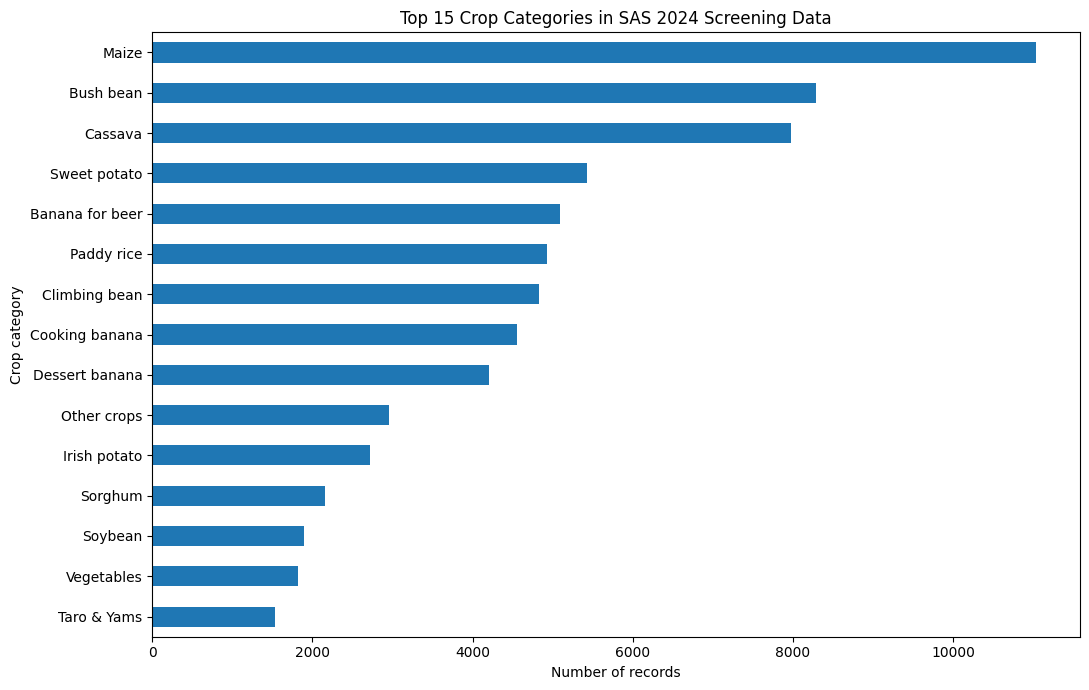

,Crop Category,Record Count
0,Maize,11036
1,Bush bean,8291
2,Cassava,7979
3,Sweet potato,5436
4,Banana for beer,5098
5,Paddy rice,4928
6,Climbing bean,4835
7,Cooking banana,4558
8,Dessert banana,4212
9,Other crops,2958


In [13]:

# 6.4 — Top 15 Crop Categories

crop_counts = (
    screening_all["CropCategory"]
    .dropna()
    .astype(str)
    .value_counts()
    .head(15)
    .sort_values()
)

plt.figure(figsize=(11, 7))
crop_counts.plot(kind="barh")
plt.title("Top 15 Crop Categories in SAS 2024 Screening Data")
plt.xlabel("Number of records")
plt.ylabel("Crop category")
plt.tight_layout()
plt.show()

display(
    crop_counts.sort_values(ascending=False)
    .rename_axis("Crop Category")
    .reset_index(name="Record Count")
)


,Records,Mean_Area_ha,Median_Area_ha,Total_Recorded_Area_ha
Season,,,,
SEASONA,47919,13.870,0.048,664650.766
SEASONB,21591,1.341,0.059,28945.721
SEASONC,4385,0.085,0.037,373.227


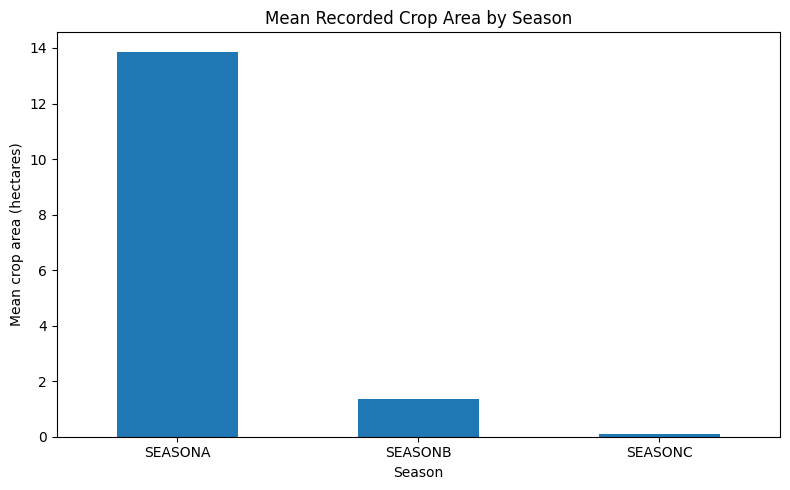

In [14]:

# 6.5 — Crop Area by Season

area_data = screening_all.dropna(
    subset=["Season", "crop_area"]
).copy()

season_summary = (
    area_data.groupby("Season")["crop_area"]
    .agg(
        Records="count",
        Mean_Area_ha="mean",
        Median_Area_ha="median",
        Total_Recorded_Area_ha="sum"
    )
    .round(3)
)

display(season_summary)

plt.figure(figsize=(8, 5))
season_summary["Mean_Area_ha"].plot(kind="bar")
plt.title("Mean Recorded Crop Area by Season")
plt.xlabel("Season")
plt.ylabel("Mean crop area (hectares)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Districts with the highest mean recorded crop area:


,Records,Mean_Crop_Area_ha,Median_Crop_Area_ha,Total_Recorded_Crop_Area_ha
s1q2,,,,
Gisagara,3392,30.983,0.050,105094.617
Nyagatare,3328,29.849,0.134,99337.128
Kayonza,2948,26.766,0.108,78905.279
Gatsibo,3543,24.002,0.087,85040.362
Kirehe,3908,23.685,0.096,92562.795
Bugesera,3935,11.680,0.069,45962.319
Ngoma,3780,9.691,0.068,36633.824
Huye,2634,9.096,0.053,23957.583
Rusizi,2464,7.862,0.058,19372.144


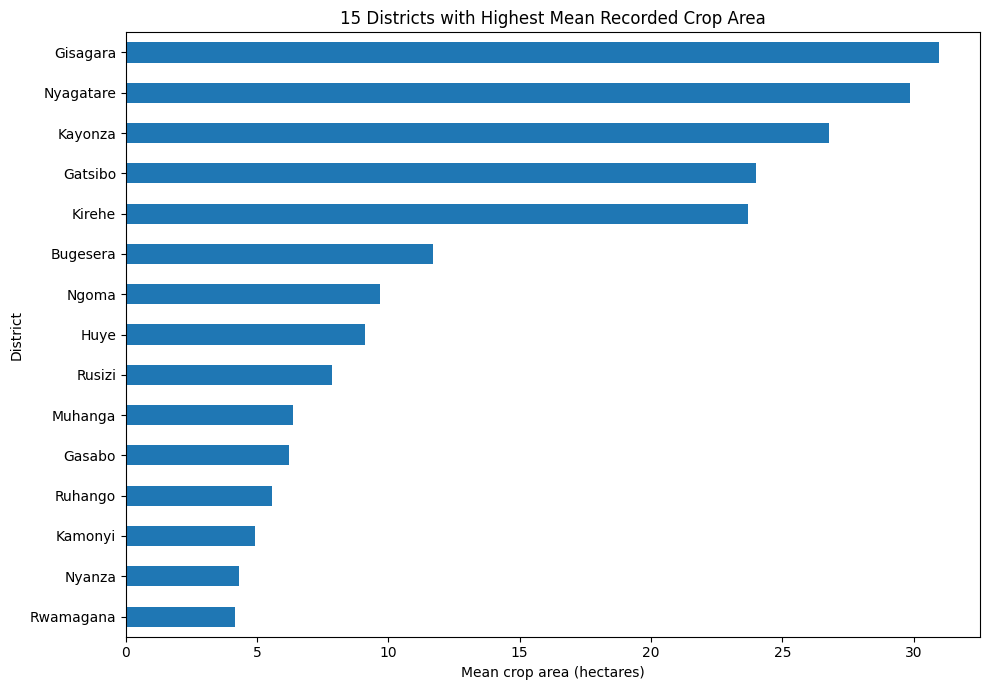

In [15]:

# 6.6 — District-Level Crop Area Summary

district_col = "s1q2"

district_data = screening_all.dropna(
    subset=[district_col, "crop_area"]
).copy()

district_summary = (
    district_data.groupby(district_col)
    .agg(
        Records=("crop_area", "count"),
        Mean_Crop_Area_ha=("crop_area", "mean"),
        Median_Crop_Area_ha=("crop_area", "median"),
        Total_Recorded_Crop_Area_ha=("crop_area", "sum")
    )
    .sort_values("Mean_Crop_Area_ha", ascending=False)
    .round(3)
)

print("Districts with the highest mean recorded crop area:")
display(district_summary.head(15))

district_summary.head(15)["Mean_Crop_Area_ha"].sort_values().plot(
    kind="barh", figsize=(10, 7)
)
plt.title("15 Districts with Highest Mean Recorded Crop Area")
plt.xlabel("Mean crop area (hectares)")
plt.ylabel("District")
plt.tight_layout()
plt.show()
